# E127: is the least-squares start's poor faithfulness in its weights or in where they sit?

**The answer.** In where they sit, and the last amendment reversed what we expected about copies. We predicted the broad lowercase copy's own weight change, moved off the subcomponents into Δ, would pass the check at about 1.24. It read 3.53, worse than the 1.91 it reads on the subcomponents. Placement cuts both ways: the least-squares split's placement makes the excess nearly four times larger, teacher training's makes it three to four times smaller. So the broad copy fails because its function is fragile under the check, and teacher training's placement hides most of that.

The first run found the start's excess is all placement: its own weight change, kept in Δ, reads better than do-nothing on both tasks. Holding the alive subcomponents fully on removes the excess, but Amendment 1 found it removes do-nothing's too, so it cannot show that those masks carry it.


## What we were trying to test

Each matrix of the released decomposition is $W = UV^\top + \Delta$: the alive subcomponents' write and read vectors in $U, V$, the rest in $\Delta$. A fine-tune changes the weights by $\delta W$. Earlier runs found that the least-squares start, the decomposition with $\delta W$ placed on the alive subcomponents by the least-squares split, reads worse under E34's adversarial check than do-nothing, where $\delta W$ sits in $\Delta$. Two things differ between them, and this run pulls them apart with a third state:

- **do-nothing**: target $W_0 + \delta W$, the update in $\Delta$.
- **least-squares start**: the alive subcomponents move to $(U + dU, V + dV)$. Its weight change is $S = (U + dU)(V + dV)^\top - UV^\top$, which drops the split's remainder, so $S \neq \delta W$.
- **same function in Δ**: target $W_0 + S$, subcomponents untouched. It computes what the start computes, with its change where do-nothing keeps its own.

The check is an adversary of 20 sign steps that sets every mask to maximise the KL divergence from the target, on 256 Pile rows. The ratio is that KL over W₀'s: 1 means the update made the decomposition no easier to break. The noise floor is 0.209, W₀'s spread over three adversary seeds.

The start's excess over do-nothing splits exactly into a **function part**, the same function in Δ minus do-nothing, and a **placement part**, the start minus the same function in Δ. Three reads then ask what carries the placement part. The **hold** fixes every alive subcomponent's mask at 1, so the adversary can move only the dead subcomponents and Δ; W₀ held against W₀ free checks that the hold changes anything. **Random masks** read the same states with no adversary. **Coherence**, $\kappa = \|\sum_c D_c\|^2 / \sum_c \|D_c\|^2$ over the per-subcomponent changes $D_c$, says whether those changes cancel: below 1 they do, and a sign-flip null reads about 1.

Two fine-tunes: lowercase, whose excess was 3.5 ratio points, and emoticon, whose excess was 0.18.


## What we expected, and why

The split keeps most of $\delta W$, so its own change should damage Pile text about as much: the lean was that the excess is placement on lowercase, and that emoticon's small excess reads within the floor. If it was placement, the hold was expected to remove it, and W₀ held was expected at 0.5 to 1.2 nats, from E20's earlier reading with the alive subcomponents kept whole. Random masks were expected not to see it, as E15 found for an earlier split state. Whether the changes cancel more on the failing states was a coin toss.


## Is the excess in the start's weights or in where they sit?


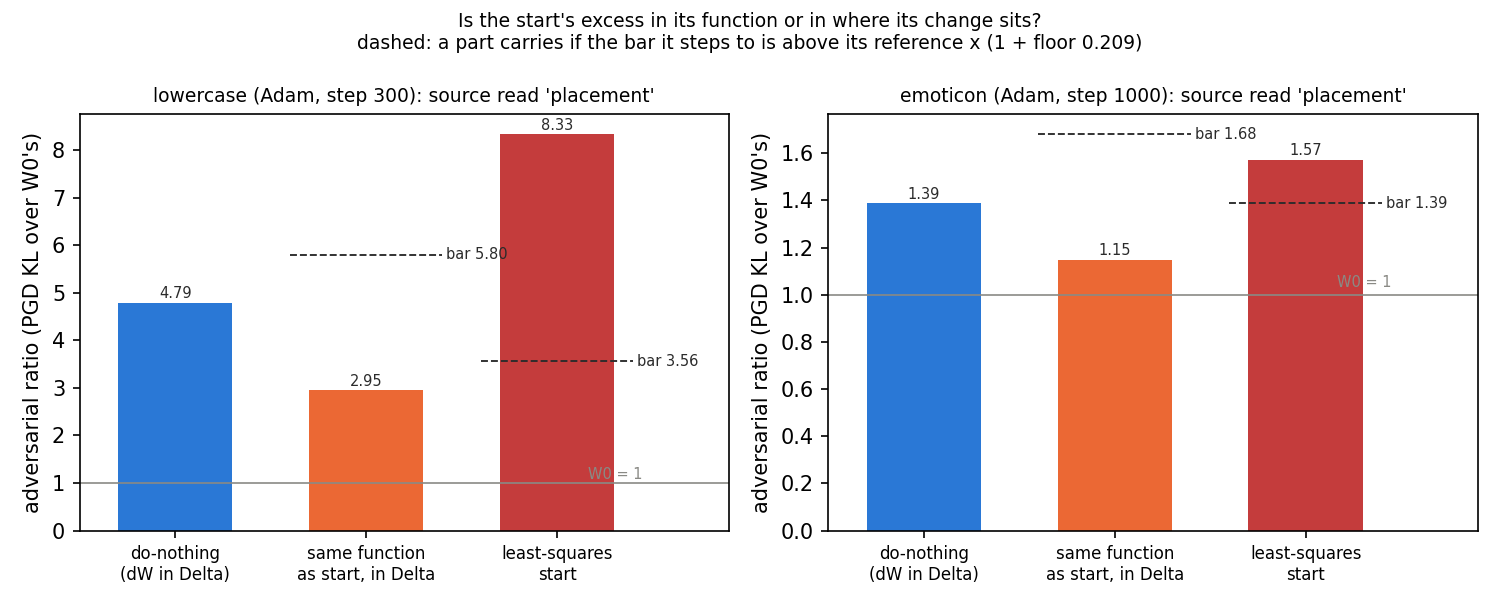

In [1]:
from IPython.display import Image

Image("../experiments/ls_start_faith/figures/source.png", width=1000)

**Reading it.** In where they sit, on both tasks. On lowercase, the start's own weight change kept in Δ reads 2.95, under do-nothing's 4.79, so the function part is negative. Moving the same weights onto the alive subcomponents takes it to 8.33, a placement part of 5.39 ratio points against a bar of 0.62. Emoticon has the same shape: 1.39, then 1.15, then 1.57. Its whole excess, 0.18, is under the floor, but the filed rule tests each part against its own bar. The placement part, 0.42, clears its bar of 0.24, so the rule reads "placement". That is the rule as filed; it rests on one adversary seed at under two floors, so emoticon is weak evidence.


## Does holding the alive masks at 1 remove the placement part?


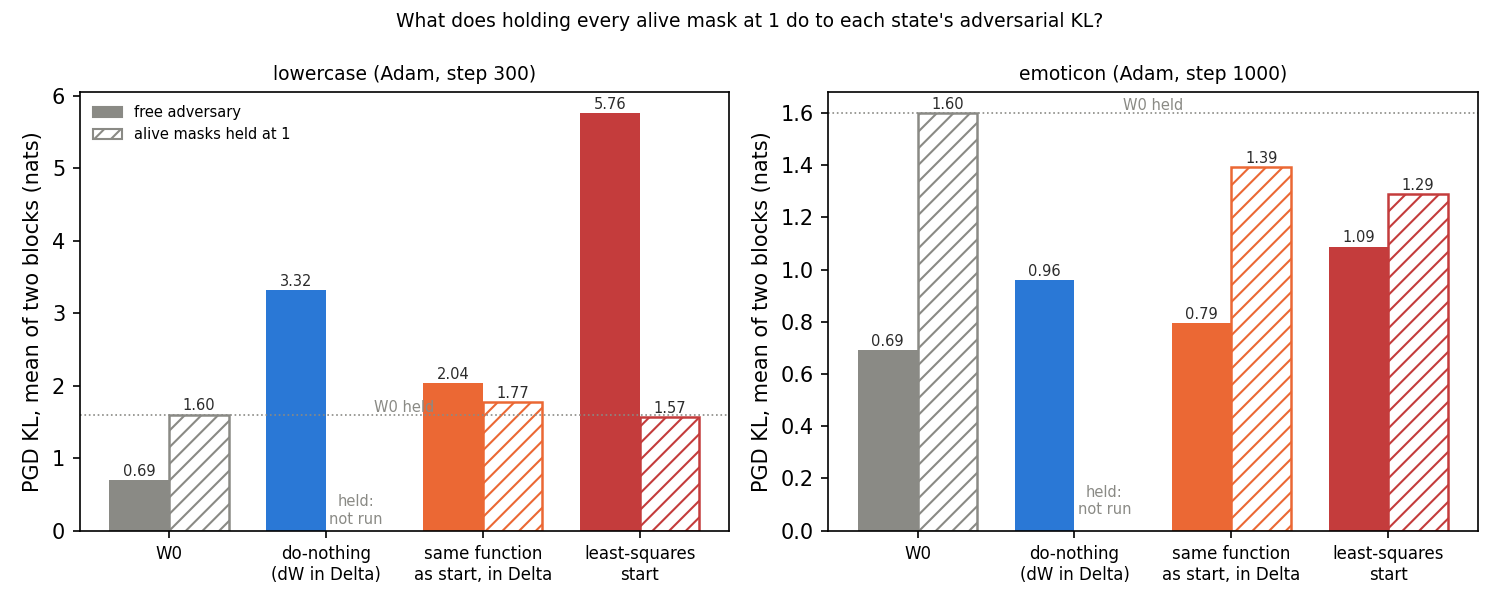

In [2]:
from IPython.display import Image

Image("../experiments/ls_start_faith/figures/hold.png", width=1000)

**Reading it.** It does, but the hold removes most of everything, so this is not yet specific to the placement. Under the hold the lowercase start reads 1.57 nats and the same function in Δ 1.77, so the placement part is gone; the filed share removed is 1.02 against a bar of 0.75.

Two things qualify this. First, the hold changes the adversary a lot: W₀ reads 1.60 nats held against 0.69 free, above the expected 0.5 to 1.2. A mask at 1 is a setting the free adversary may choose, so the 20-step free search is not finding the strongest masks at W₀. Held ratios therefore divide by a different, larger number; computed in nats, the share removed is still 1.06 on lowercase. Second, the same function in Δ has no change on the alive subcomponents, yet the hold cuts its excess over W₀ from 1.35 nats to 0.17. If the hold flattens every state, it says nothing about the placement. Do-nothing under the hold, marked "not run" in the figure, is the read that decides; Amendment 1, next, reads it.


## Amendment 1: under the hold, does do-nothing keep its excess?

The hold flattened the start, and also the same function in Δ, whose change sits outside the alive subcomponents. If it flattens do-nothing as well, the held check has lost its ability to see any excess, and the hold reading says nothing about the alive masks. So the amendment read three more states with every alive mask held at 1, on the same rows, seed and card:

- **do-nothing**, the hold's positive control. Its free excess on lowercase is 3.79 ratio points, 18 floors, so a hold with teeth should leave a large part of it;
- **the standard teacher-trained copy** of the same fine-tune, free and held;
- **the copy trained from the least-squares start**, free and held, for description only.

The filed rule: the hold has teeth if do-nothing held keeps at least half of its free excess, and at least one floor, both as ratios over W₀ read the same way. If not, E127's hold reading is reported "unreadable under the hold". The lean was "no teeth".

**The job stopped on a control at its ninth of twelve reads.** Each copy's free read must reproduce the reading stored when the copy was made. Every lowercase read did so exactly. The emoticon standard copy read 1.007 against a stored 0.987, a miss of 2.1% against a band of 1%. This is most likely bf16 rounding: E121 read that copy in fp32 but saved it only as bf16 offsets, which is what this job read. The cause is not proven. Lowercase, the headline task, is complete; on emoticon only do-nothing held was read. The lead decided not to rerun the emoticon copies, since the emoticon teeth reading is already "no teeth" and they could not change a verdict.


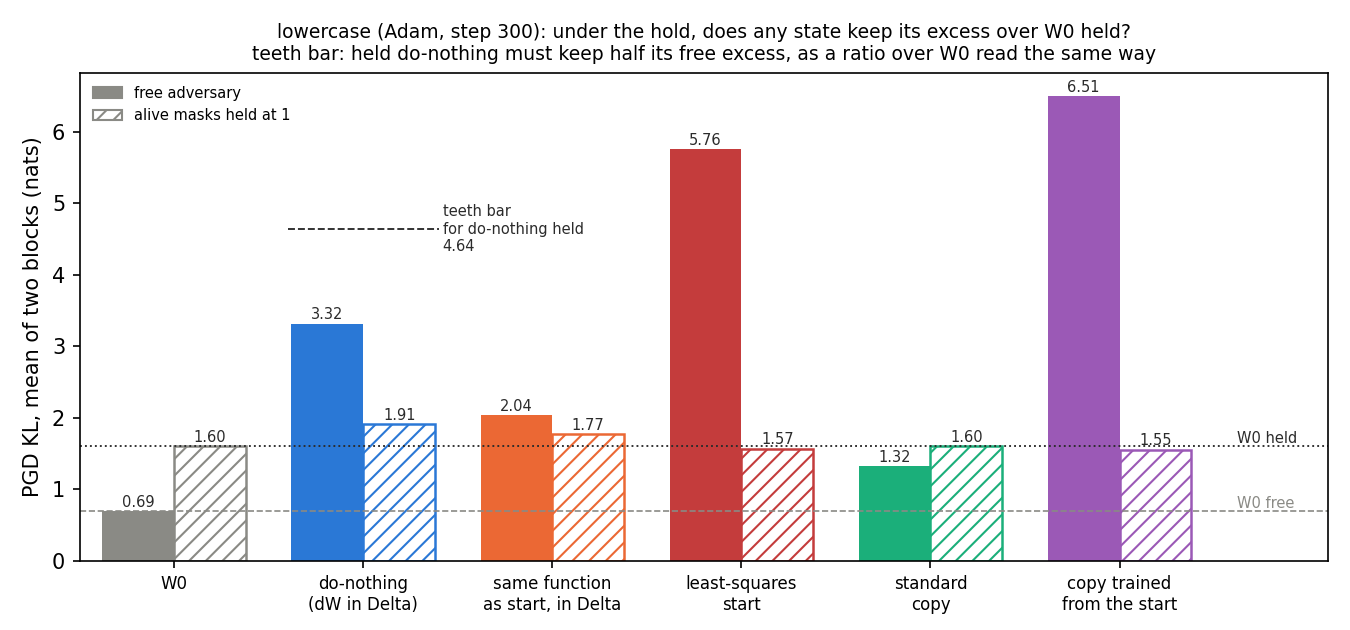

In [3]:
from IPython.display import Image

Image("../experiments/ls_start_faith/figures/amend1_hold.png", width=1000)

**Reading it.** No: the hold has no teeth. Do-nothing reads 3.32 nats free and 1.91 held, against W₀'s 0.69 free and 1.60 held. As a held ratio that is 1.19, about 5% of its free excess, where the bar asked for 1.90. Both copies fall to W₀'s held line too: the standard copy from 1.91 free to 1.00 held, the copy from the start from 9.40 to 0.97. Every state ends within 0.31 nats of W₀ held, whatever its free reading and wherever its change sits. On emoticon, do-nothing held reads 0.88, under W₀ held, so the hold has no teeth there either.

So the hold takes away the adversary's ability to find any excess, not the placement's in particular. What still stands from E127 is everything read without the hold: the start's own weight change in Δ reads better than do-nothing, and placing it on the alive subcomponents carries the whole excess. What falls is the claim that the hold isolates the placed update.


## Amendment 2: would the broad copy's own change pass if it sat in Δ?

**Something unexpected happened.** The filed lean, from Fable, was that the standard lowercase copy's change would read 1.24 in Δ and pass. It read 3.53, nearly eight floors above even the null of "no change from 1.91".

On lowercase the start reads 3.77 times as much excess over W₀ on the alive subcomponents as in Δ. The standard teacher-trained copy of the same fine-tune fails at 1.91, over the fail line of 1.61. If every change on the subcomponents reads about 3.8 times its in-Δ excess, the copy's own function should pass in Δ, and it fails only because of where it sits. So each copy's weight change $S_c = U'V'^\top - UV^\top$ was read twice: as the copy, with the alive subcomponents at $(U', V')$, and in Δ, with target $W_0 + S_c$ and the subcomponents left at the released $(U, V)$. At full masks the two are the same weights.

Three copies, all made by the same teacher training on lowercase rows: the **standard copy**, started from W₀'s subcomponents; the **copy from the start**, started from the least-squares start; and the **copy of a rank-8 LoRA** fine-tune on the same task, which passes. The filed rule: the standard copy's change in Δ under 1.40 means "placement explains the broad failure", over 1.82 "function fails too". W₀ and each copy's free read reproduced their stored values exactly.


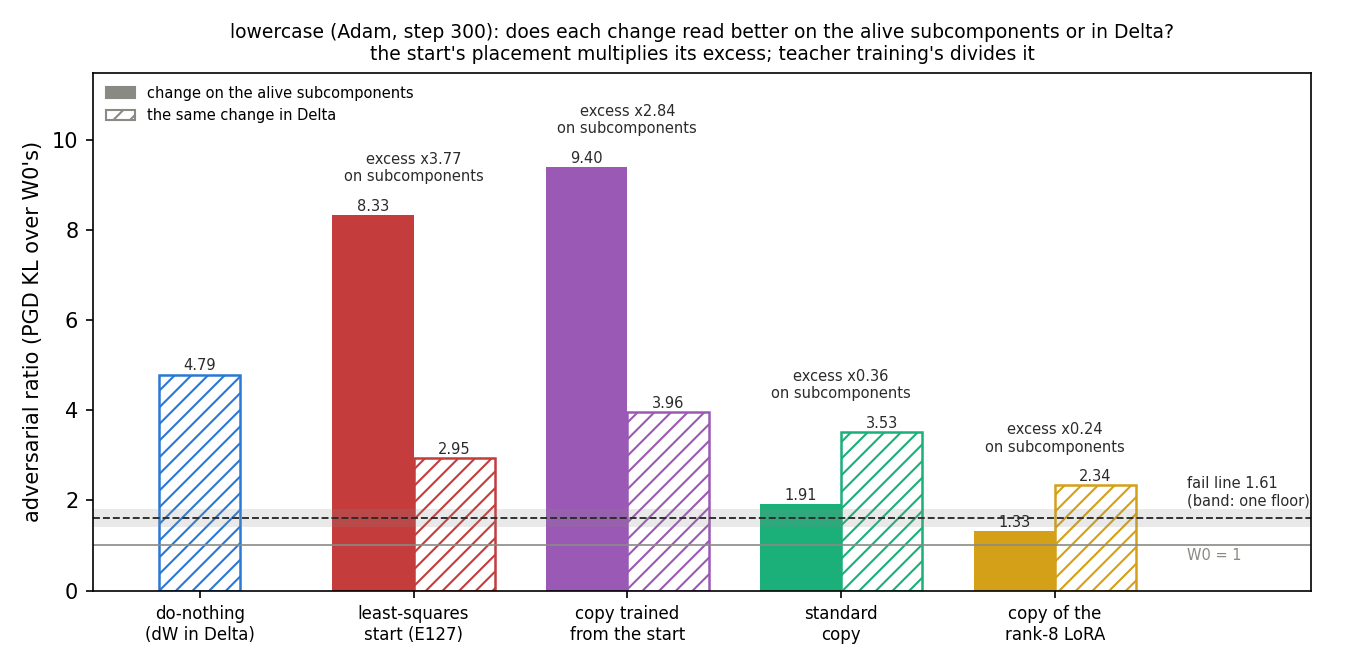

In [4]:
from IPython.display import Image

Image("../experiments/ls_start_faith/figures/amend2_delta.png", width=1000)


**Reading it.** The broad copy's function fails in Δ, and how a change was placed decides whether the subcomponents help or hurt. The standard copy's change reads 1.91 on the subcomponents and 3.53 in Δ, so the filed reading is "function fails too". Teacher training's placement shrinks the excess, by 2.8 times for the standard copy and 4.1 times for the LoRA copy. The least-squares split's placement grows it by 3.8 times, and the copy trained from the start keeps most of that. Every copy's change fails in Δ, the LoRA copy's at 2.34 included, where the fine-tune's own change reads 4.79.

Teacher training's loss has no mask in it: it is the KL from the fine-tuned model at full masks, with no causal importance, random mask or adversary. So its protective placement is not by design. One untested reason: the gradient lands on subcomponents whose read vectors see the training inputs, plausibly those Γ keeps on there, and the adversary cannot push a mask below its causal importance.

The caveat is that the two placements give the adversary different freedoms. In Δ the change shares one mask per matrix with W₀'s own Δ; on the subcomponents each rides its own mask between its causal importance and 1. "Fragile function" means fragile with the change placed in Δ.


## Do random masks see the placement part?


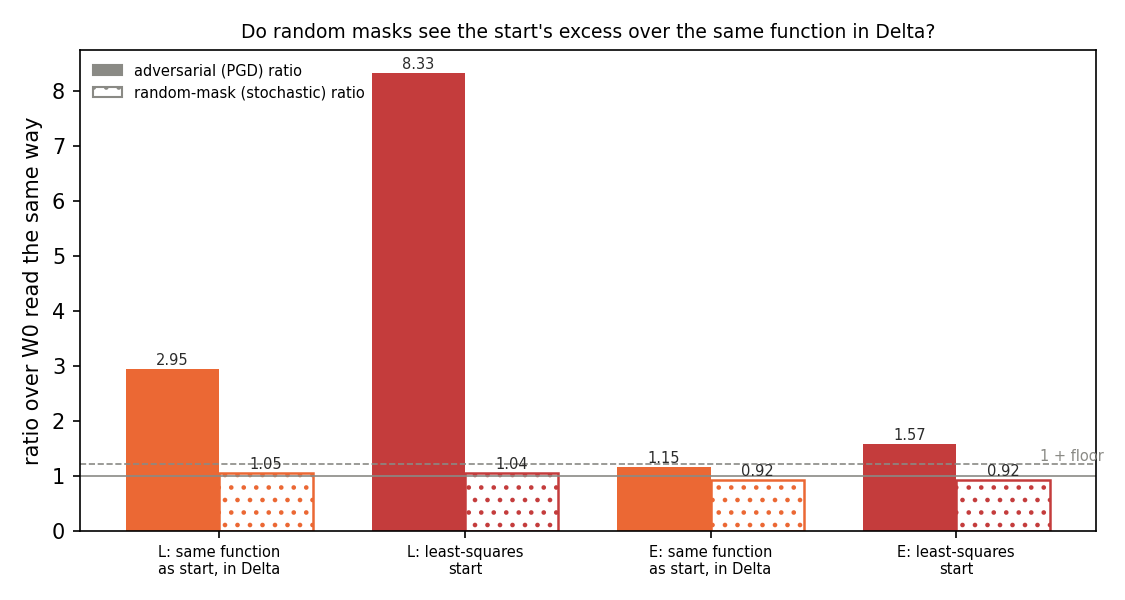

In [5]:
from IPython.display import Image

Image("../experiments/ls_start_faith/figures/random.png", width=1000)

**Reading it.** No: only the adversary sees it. Under random masks the start and the same function in Δ read within 1% of each other on both tasks, while the adversary puts them 5.39 ratio points apart on lowercase. All four random-mask ratios sit near 1, inside the expected 0.9 to 1.2. The random read's own noise was not measured.


## Do the per-subcomponent changes cancel on the failing states only?


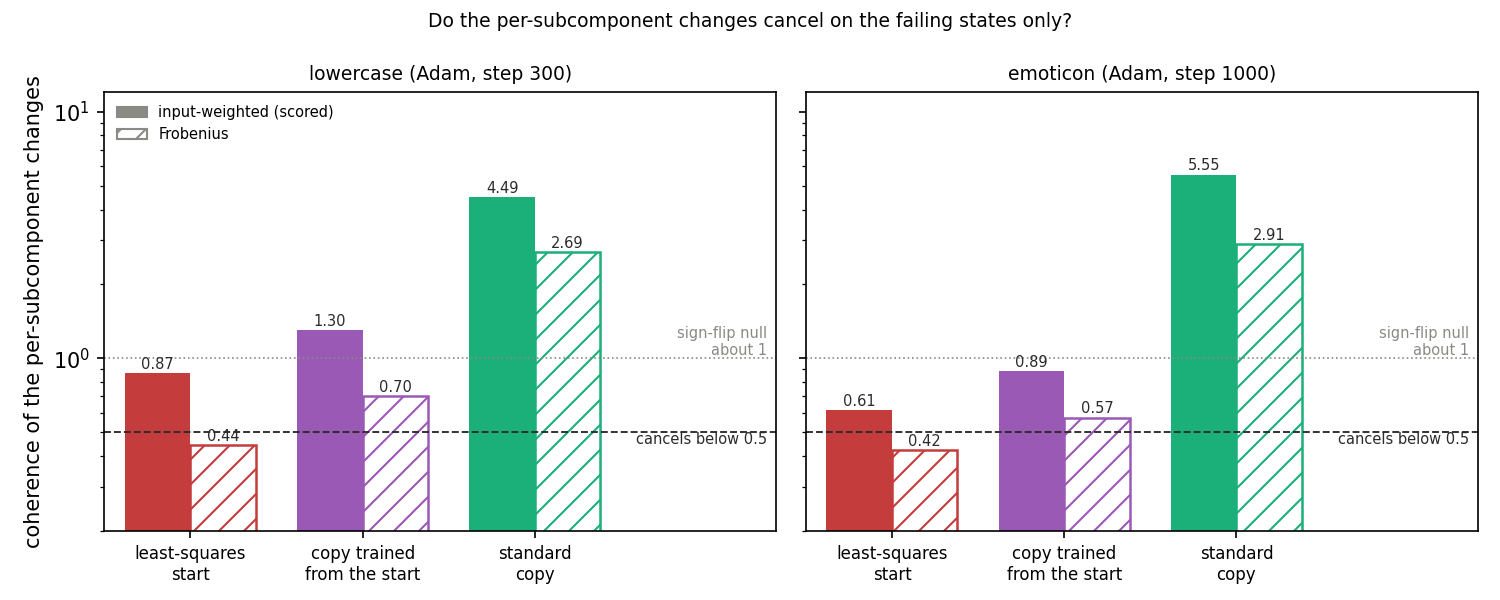

In [6]:
from IPython.display import Image

Image("../experiments/ls_start_faith/figures/coherence.png", width=1000)

**Reading it.** No. Input-weighted, the start reads 0.87 on lowercase and 0.61 on emoticon, above the cancelling bar of 0.5, and the copy trained from the start, which keeps the excess, reads 1.30 and 0.89. The standard copy's changes add up strongly, at 4.49 and 5.55. Frobenius coherence puts the start below 0.5, matching E17's 0.44, but the copy from the start still does not cancel. Cancellation separates the start from the standard copy, not the failing states from the faithful one.


## What we learned

The least-squares start's poor faithfulness on these fine-tunes comes from placing the change on the alive subcomponents, not from dropping the split's remainder: the dropped part, if anything, helps. Amendment 2 shows the cost is the least-squares split's placement, not placement in general. Teacher training's placement of a change makes it three to four times harder to exploit than the same change in Δ, though nothing in its loss asks for that. The broad lowercase copy fails because the function it copies is fragile under the check, and its placement hides most but not all of it; the LoRA copy's smaller excess ends under the line. For `GOALS.md`, keeping a decomposition faithful along training depends on where the update is placed on the subcomponents, and a loss that asks for a protected placement directly is one candidate.

## How compelling is the evidence

Lowercase's placement part is about nine times its bar; emoticon's is under two, from one adversary seed. One row set, one fine-tune per task, one L40. On lowercase the hold was read on all six states, and do-nothing kept about 5% of its free excess, far under the bar of half. Amendment 2's headline sits eight floors past its edge, but on one seed and one task, with three copies of one recipe. "Fragile function" is read with the change in Δ only, where the adversary's freedom differs.

## Surprises

- **Amendment 2 reversed the filed expectation**: the standard copy's change in Δ was predicted at 1.24, a pass, and read 3.53; the LoRA copy's was predicted at 1.09 and read 2.34.
- The function part is negative on both tasks: the same function in Δ reads 2.95 on lowercase, where 4 to 6 was expected.
- W₀ held reads 1.60 nats, above the expected 0.5 to 1.2: the free adversary at W₀ finds less than a setting it is allowed.
- Emoticon read "placement", where "within the floor" was expected, because the rule tests each part, not the whole excess.
- Amendment 1 stopped on the emoticon standard copy's free read, 1.007 against a stored 0.987; most likely bf16 rounding of the saved copy, not proven.

## What next

E127 has no amendment slots left; each item is a new plan.

- **Where each change sits against the causal importances** on the check's rows, for the start and the standard copy. If teacher training's change sits on subcomponents Γ keeps on and the start's does not, the placement is explained.
- **Teacher training with a faithfulness term in its loss.** If the broad Adam copy then passes, placement is the lever for broad updates; if not, the function is the limit.
- **A stronger free adversary at W₀**, more steps or restarts. If it reaches 1.60, every free ratio has been read against a weak denominator.


## Scorecard

| rule | read | lean | verdict |
|---|---|---|---|
| A lowercase: function or placement | function −1.85, placement 5.39 | placement 0.5 | placement |
| A emoticon | function −0.24, placement 0.42 | within the floor 0.6 | placement; lean missed |
| B lowercase: hold removes it, H ≥ 0.75 | H 1.02 | alive masks 0.5 | the alive masks as filed; unreadable under the hold |
| B emoticon, reported only | H 1.15 | none | the alive masks as filed; unreadable under the hold |
| C both: random masks, q ≥ 0.209 | q −0.009, 0.005 | adversary only 0.8 | adversary only |
| D both: start and copy from it κ < 0.5, standard not | 0.87, 1.30; 0.61, 0.89 | 0.5 / 0.5 | does not track |
| A1 R1 lowercase: teeth, do-nothing held − 1 ≥ 1.90 | 0.19 | no teeth 0.85 | no teeth |
| A1 R1 emoticon: teeth, bar 0.209 | −0.12 | no teeth 0.8 | no teeth |
| A1 R2 lowercase: standard copy | 1.91 free → 1.00 held | exposed 0.65 | exposed |
| A1 R2 emoticon | not read | out of reach 0.65 | not run |
| A2 R1: standard copy in Δ, < 1.40 placement, > 1.82 function | 3.53 | placement explains 0.5 | **function fails too; reversed** |
| A2 R2: multiplier, standard / from start / LoRA | 0.36 / 2.84 / 0.24 | about 3.8 | descriptive |

| expected | read | verdict |
|---|---|---|
| controls reproduce E121 and E122 | exact | held |
| W₀ held 0.5-1.2 nats | 1.60 | missed |
| same function in Δ, lowercase, 4-6 | 2.95 | missed |
| random-mask ratios 0.9-1.2 | 0.92-1.05 | held |
| start κ 0.3-0.6 | 0.87, 0.61 | missed |
| standard copy κ 2-4 | 4.49, 5.55 | missed |
| A1: emoticon copies reproduce within 1% | 1.007 vs 0.987 | missed; job stopped |
| A2: standard copy in Δ 1.10-1.45 | 3.53 | missed, high |
| A2: copy from the start in Δ 2.4-4.5 | 3.96 | held |
| A2: controls, W₀ and three copies free | exact | held |

The full list is in the report.

## Not run

- Amendment 1's emoticon reads after the stop: the standard copy held, the copy from the start free and held. Not rerun, by the lead's decision: they could not change the emoticon "no teeth" reading.
- A measured bf16 floor for the emoticon copies, which would confirm or rule out rounding as the cause of the stop.
- Amendment 2 on emoticon, whose copy has no excess to divide; on other seeds or Pile set B.
- The LoRA fine-tune's own do-nothing on the L40; E39 read it on an H100.
- Where each change sits against the causal importances; teacher training with a faithfulness term.
- Adversary seeds 1 and 2; a stronger free adversary; a hold at the CI values or on a subset of subcomponents; the random read's noise floor.

**Provenance.** `experiments/ls_start_faith/results/ls_start_faith.json`, `ls_start_faith_amend1.json` and `ls_start_faith_amend2.json`; report `reports/analyses/2026-11-06_analysis_e127-ls-start-faithfulness.md`; MATS debug L40 jobs 54836 and 54874, about 31 min; Amendment 1's job 54890, about 19 min, stopped with exit 1; Amendment 2's job 54934, 15.5 min, exit 0; $0.
